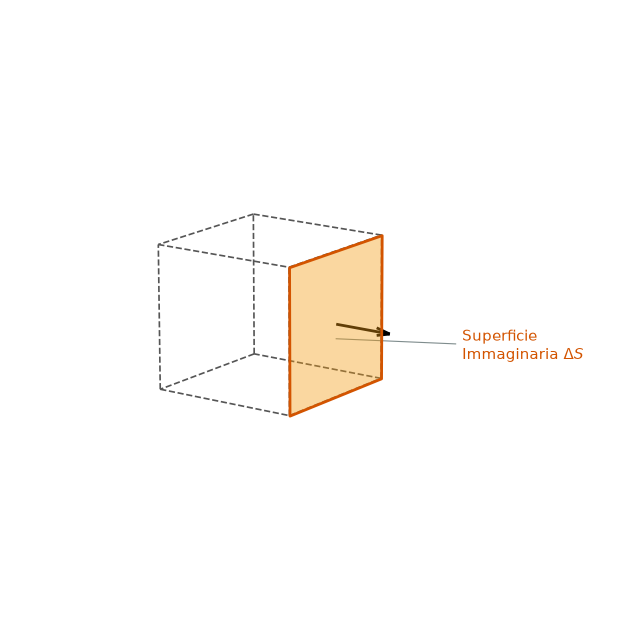

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

# Configurazione della figura con sfondo bianco pulito
fig = plt.figure(figsize=(12, 8), facecolor='white')
ax = fig.add_subplot(111, projection='3d', facecolor='white')

# --- 1. DEFINIZIONE DEL CUBETTO (Volume Delta V) ---
# Dimensioni del cubo (da 0 a 2 lungo i tre assi)
L = 2.0
vertices = np.array([
    [0, 0, 0], [L, 0, 0], [L, L, 0], [0, L, 0],  # Base inferiore (0,1,2,3)
    [0, 0, L], [L, 0, L], [L, L, L], [0, L, L]   # Base superiore (4,5,6,7)
])

# Spigoli del cubo da disegnare come linee tratteggiate
edges = [
    (0,1), (1,2), (2,3), (3,0),  # Base inferiore
    (4,5), (5,6), (6,7), (7,4),  # Base superiore
    (0,4), (1,5), (2,6), (3,7)   # Collegamenti verticali
]

for edge in edges:
    ax.plot3D(
        *zip(vertices[edge[0]], vertices[edge[1]]), 
        color="#555555", 
        linestyle="--", 
        linewidth=1.2
    )

# --- 2. EVIDENZIAZIONE DELLA SUPERFICIE DELTA S ---
# Evidenziamo la faccia destra (x = L), definita dai nodi 1, 2, 6, 5
face_ds = [vertices[[1, 2, 6, 5]]]
surface_poly = Poly3DCollection(
    face_ds, 
    facecolor='#f39c12',  # Colore arancione accattivante ma scientifico
    edgecolor='#d35400', 
    linewidth=2, 
    alpha=0.4,            # Semi-trasparente
    label=r'$\Delta S$'
)
ax.add_collection3d(surface_poly)

# --- 3. VETTORE NORMALE (n) ---
# Il vettore parte dal centro della faccia Delta S (x=2, y=1, z=1) e punta verso l'esterno (+x)
start_x, start_y, start_z = L, L/2, L/2
direction_x, direction_y, direction_z = 0.8, 0, 0

ax.quiver(
    start_x, start_y, start_z, 
    direction_x, direction_y, direction_z, 
    color='black', 
    linewidth=2, 
    arrow_length_ratio=0.25
)
# Richiamo per la superficie immaginaria
ax.plot3D([L, L + 0.8], [L/2, L + 0.5], [L/2 - 0.2, L/2 - 0.5], color='#7f8c8d', linestyle='-', linewidth=0.8)
ax.text(L + 0.9, L + 0.5, L/2 - 0.7, "Superficie\nImmaginaria $\\Delta S$", fontsize=11, color='#d35400')


# --- 5. CORREZIONE DELLA PROSPETTIVA E DELLO STILE ---
# Impostazione dell'angolo di visualizzazione per una prospettiva ottimale
ax.view_init(elev=15, azim=-55)

# Rimozione degli assi, griglie e background per un look "diagramma isolato"
ax.set_axis_off()

# Limiti degli assi per centrare il disegno
ax.set_xlim(-1, 4)
ax.set_ylim(-1, 4)
ax.set_zlim(-1, 3)

# Mostra il grafico
plt.show()